# Reading an SU2 CFD mesh

**SU2** is an open-source suite for computational fluid dynamics (CFD) and PDE-constrained optimisation. Its native `.su2` mesh format lists points and elements by VTK cell code (triangles = 5, quads = 9) and is **0-based**. `pyramids-mesh` reads it into a `pyramids.netcdf.ugrid.UgridDataset`, turning a CFD grid into an ordinary pyramids object.

This sample is `5x5Mesh.su2` from the SU2 test cases — a clean **5x5 grid of 25 quadrilateral cells** on the unit square (LGPL data).

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

## 3. Locate the example data

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels up. Paths inside a notebook are written **relative to the notebook itself**. The critical rule for `read_file` is to pass a `pathlib.Path`, never `str(...)`. We read `su2/5x5Mesh.su2`.

In [2]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "su2" / "5x5Mesh.su2"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/su2/5x5Mesh.su2'), True)

## 4. Quickstart: read the file

`UgridDataset.read_file(path, driver=...)` parses the file and returns a `UgridDataset` — the same type pyramids produces from a NetCDF UGRID file. We name the `"su2"` driver explicitly; passing the **`Path`** object (not a string) is the supported call.

In [3]:
ds = UgridDataset.read_file(mesh_file, driver="su2")
type(ds).__name__

'UgridDataset'

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

## 5. Explore the dataset

A `UgridDataset` exposes summary properties: `n_node` / `n_face` (mesh size), `crs` / `epsg` (georeferencing if the format recorded any), `bounds` (the `(minx, miny, maxx, maxy)` extent), and `data_variable_names` (attached field variables).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": tuple(round(float(b), 3) for b in ds.bounds),
    "data_variable_names": ds.data_variable_names,
})

n_node                                   36
n_face                                   25
crs                                    None
epsg                                   None
bounds                 (0.0, 0.0, 1.0, 1.0)
data_variable_names                      []
dtype: object

`crs`/`epsg` are `None`: a CFD mesh lives in dimensionless or physical model coordinates, not a geographic CRS. The extent is the unit square `(0, 0, 1, 1)`. `data_variable_names` is empty — the `.su2` file is the grid; flow fields come from the solver output.

## 6. Face-degree distribution

`ds.mesh.face_node_connectivity.data` is the `(n_face, k)` table of node indices per face, where `k` is the widest polygon. Cells with fewer nodes than `k` are **padded with `-1` (fill)**. Counting the non-negative entries per row gives each face's number of nodes — its *degree*.

In [6]:
conn = ds.mesh.face_node_connectivity.data
degree = (conn >= 0).sum(axis=1)
vals, counts = np.unique(degree, return_counts=True)
dist = pd.Series(dict(zip(vals.tolist(), counts.tolist())), name="n_faces")
dist.index.name = "nodes_per_face"
{"degree_distribution": dist.to_dict(), "fill_slots(-1)": int((conn == -1).sum())}

{'degree_distribution': {4: 25}, 'fill_slots(-1)': 0}

All 25 cells have **4 nodes** with no `-1` fill — a structured block of quadrilaterals (VTK code 9). SU2 meshes can also be triangular (code 5; the sibling `square.su2`), which would show degree 3 here instead.

## 7. The underlying geometry

`ds.mesh` is the `Mesh2d` holding the raw arrays: `node_x` / `node_y` (coordinates), the connectivity table, `face_areas` (one area per cell) and `face_centroids` (shape `(2, n_face)`). Everything geometric is derived from the connectivity plus the node coordinates.

In [7]:
mesh = ds.mesh
conn = mesh.face_node_connectivity.data
areas = mesh.face_areas
cent = np.asarray(mesh.face_centroids)  # (2, n_face)
{"conn_shape": conn.shape, "n_node": mesh.node_x.shape[0],
 "areas_minmax": (round(float(areas.min()), 4), round(float(areas.max()), 4)),
 "centroids_shape": cent.shape}

{'conn_shape': (25, 4),
 'n_node': 36,
 'areas_minmax': (0.04, 0.04),
 'centroids_shape': (2, 25)}

## 8. Wireframe: `plot_outline()`

The simplest view needs no data — just the mesh edges. `plot_outline()` draws the wireframe through cleopatra and embeds it inline. This is the fastest sanity check that a file read in correctly.

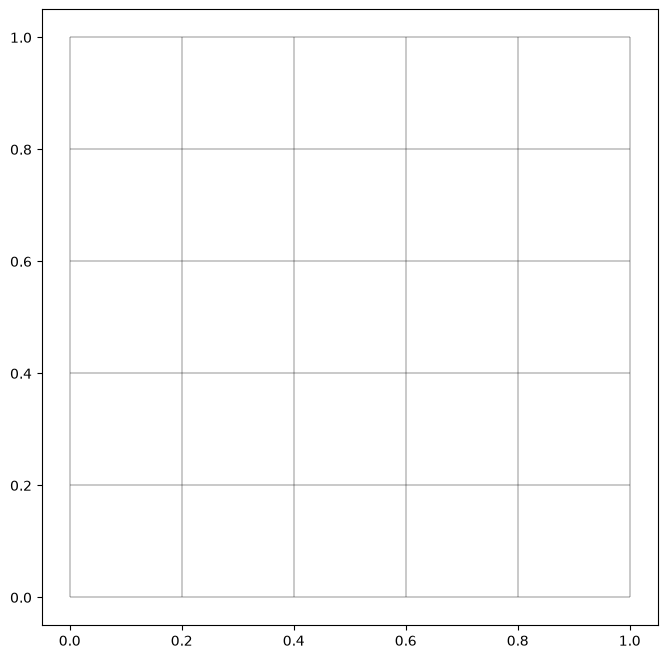

In [8]:
ds.plot_outline()


A tidy 5x5 checkerboard of unit-square quads — the structured CFD grid exactly as stored. Each of the 25 cells has area 0.04, consistent with a uniform subdivision of the unit square.

## 9. A data map: attach and colour a field

To draw a *filled* map we need a value per cell. These mesh files carry geometry only, so we compute one — each cell's area — and attach it with `with_variable(..., location="face")`, which returns a **new** dataset (the original `ds` is untouched). Then `plot` colours the mesh by it.

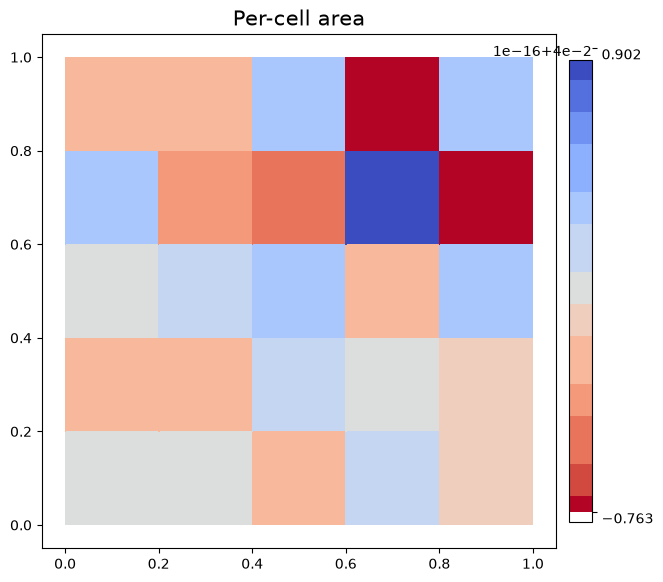

In [9]:
d2 = ds.with_variable("cell_area", ds.mesh.face_areas, location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="Per-cell area")


Each cell is now shaded by its area. This is the generic pyramids data-map path — any per-cell field (water depth, velocity, head) plots exactly the same way.

### The statistical summary

With a field attached, `.summary()` reports per-variable statistics (count, min, max, mean, std). On the bare `ds` it is an empty frame; on `d2` it has a real row.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
cell_area,25,0.04,0.04,0.04,3.663841e-17


## 10. GIS operations, for free

Because the mesh is now a first-class pyramids object, the pyramids GIS layer applies directly — `pyramids-mesh` itself adds none of this. The next cells each run one operation and interpret it.

### Faces as a GeoDataFrame

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((0 0, 0.2 0, 0.2 0.2, 0 0.2, 0 0))"
1,"POLYGON ((0.2 0, 0.4 0, 0.4 0.2, 0.2 0.2, 0.2 0))"
2,"POLYGON ((0.4 0, 0.6 0, 0.6 0.2, 0.4 0.2, 0.4 0))"
3,"POLYGON ((0.6 0, 0.8 0, 0.8 0.2, 0.6 0.2, 0.6 0))"
4,"POLYGON ((0.8 0, 1 0, 1 0.2, 0.8 0.2, 0.8 0))"


Plotting that GeoDataFrame draws the mesh footprint as vector polygons (one patch per cell).

<Axes: xlabel='x', ylabel='y'>

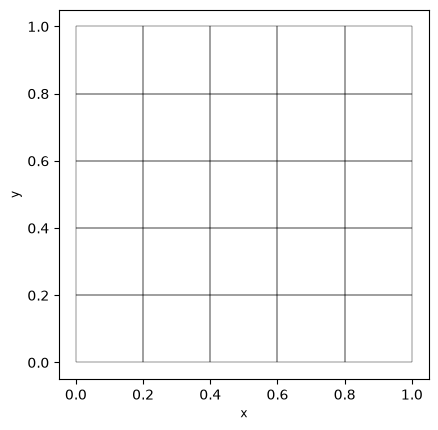

In [12]:
gdf.plot(edgecolor="black", facecolor="none", linewidth=0.3)


### Bounding polygon

`bounding_polygon()` dissolves the cells into a single shapely polygon of the meshed footprint — the gateway to the shapely/geopandas ecosystem for clipping and spatial joins.

In [13]:
poly = ds.bounding_polygon()
poly.geom_type, tuple(round(float(b), 3) for b in poly.bounds)

('Polygon', (0.0, 0.0, 1.0, 1.0))

### Circumcenters — explain and skip

`circumcenters()` is **only defined for triangular meshes**. This mesh is not all-triangle, so the call raises `ValueError`; we catch it rather than crash. (Use cell centroids instead for such grids.)

In [14]:
try:
    ds.circumcenters()
except ValueError as e:
    print("skipped circumcenters:", e)

skipped circumcenters: circumcenters is only defined for triangular meshes.


### Exterior edges

`exterior_edges()` returns the node indices of the mesh **boundary** — the edges that belong to exactly one cell. Its length is a quick measure of how much perimeter the mesh has.

In [15]:
edges = ds.exterior_edges()
edges.shape, edges[:6].tolist()

((20,), [0, 3, 4, 7, 10, 13])

20 boundary-edge entries trace the outer square — the 5+5+5+5 perimeter edges of the 5x5 block. Interior edges shared by two quads are excluded.

### Cell adjacency and connected components

`sparse_adjacency()` is the cell-to-cell adjacency as a SciPy sparse matrix (`nnz` = twice the number of shared internal edges). `connected_components()` labels which cells are mutually reachable through that adjacency.

In [16]:
adj = ds.sparse_adjacency()
labels = ds.connected_components()
{"adjacency_shape": adj.shape, "nnz": int(adj.nnz),
 "n_components": int(np.unique(labels).size)}

{'adjacency_shape': (25, 25), 'nnz': 80, 'n_components': 1}

A single connected component: the structured block is fully contiguous, every quad reachable across shared edges. `nnz` counts the internal face-neighbour links.

### Subset by a bounding box

`subset_by_bounds(xmin, ymin, xmax, ymax)` keeps only the cells inside a window (note the four positional coordinates, not a tuple). We take the centred 60% window and plot the result — a clean clip that returns a new `UgridDataset`. (`crop(bbox=...)` does the same thing with a tuple argument.)

In [17]:
b = ds.bounds
cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
hx, hy = (b[2] - b[0]) * 0.3, (b[3] - b[1]) * 0.3
sub = ds.subset_by_bounds(cx - hx, cy - hy, cx + hx, cy + hy)
{"full_n_face": ds.n_face, "subset_n_face": sub.n_face}

{'full_n_face': 25, 'subset_n_face': 9}

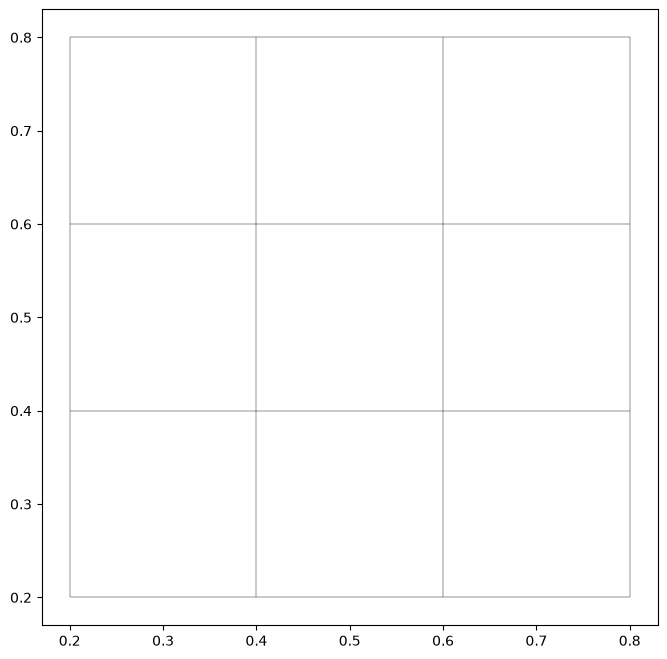

In [18]:
sub.plot_outline()


The centred 60% window keeps the inner 3x3 core of quads and drops the outer ring — a structured-grid clip returning a valid `UgridDataset`.

### Export: xarray and NetCDF round-trip

`to_xarray()` hands back an `xarray.Dataset` (the UGRID representation), and `to_file(path)` writes a NetCDF UGRID file — the canonical pyramids on-disk form that any UGRID reader can load back.

In [19]:
import tempfile, os
xds = ds.to_xarray()
out = os.path.join(tempfile.gettempdir(), "mesh_roundtrip.nc")
ds.to_file(out)
{"xarray_type": type(xds).__name__, "nc_bytes": os.path.getsize(out)}

{'xarray_type': 'Dataset', 'nc_bytes': 13216}

## 11. CRS-dependent operations — explain and skip

This format records **no CRS** (`crs` / `epsg` were `None` above), so coordinate-aware steps have nothing to work from:

- **`to_crs(...)`** — a reprojection needs a *source* CRS; with `None` there is nothing to reproject from, so we skip it. In practice you would first assign the CRS you know the model used.
- **`rasterize_like(...)` / `regrid(...)`** — these burn the mesh onto, or resample it to, a target **raster grid**. That is the job of the `pyramids-gis` raster layer (you supply a target `Dataset`); it is out of scope for a format-reader tutorial, so we only name it here.

In [20]:
ds.crs  # None -> no reprojection target; to_crs / rasterize_like / regrid skipped

## 12. Takeaway

- **SU2 `.su2` = native CFD mesh**: VTK-coded, 0-based points and elements, read into a `UgridDataset`.
- This sample is a structured 5x5 block of quads (degree 4, no `-1` fill); triangular SU2 meshes also exist.
- Quads, so `circumcenters()` is skipped; no CRS, so reprojection/rasterisation are skipped.
- Explore, plot and GIS (footprint, bounding polygon, box-subset) all work on the CFD grid as on any mesh.